# ECG Signal Processing & Analysis using Python

## Overview
This beginner-friendly Digital Signal Processing (DSP) project demonstrates how to process and analyze raw Electrocardiogram (ECG) signals using Python.

### What is an ECG?
An **Electrocardiogram (ECG)** measures the electrical activity of the heart over time using electrodes placed on the skin. A typical cardiac cycle consists of:
* **P wave**: Atrial depolarization (atria contracting).
* **QRS complex**: Ventricular depolarization (ventricles contracting to pump blood). The **R-peak** is the sharpest, highest peak.
* **T wave**: Ventricular repolarization (ventricles recovering/relaxing).

```
        R
       / \
      /   \
 P   /     \   T
/ \ /       \ / \
   Q         S
```

---

### DSP Pipeline in this Notebook
1. **Signal Acquisition**: Load ECG recording `101` from the local MIT-BIH dataset using `wfdb`.
2. **Signal Visualization**: Inspect the raw time-domain ECG waveform.
3. **Preprocessing**: Design and apply a Butterworth band-pass filter (0.5 – 40 Hz) to eliminate baseline wander and high-frequency noise.
4. **Frequency Analysis**: Apply the Fast Fourier Transform (FFT) to compare frequency spectra before and after filtering.
5. **R-Peak Detection**: Detect heartbeat R-peaks using `scipy.signal.find_peaks` with physiological constraints.
6. **Heart Rate Estimation**: Calculate R-R intervals, instantaneous heart rate, and average BPM.
7. **Evaluation**: Benchmark detected peaks against cardiologist ground-truth annotations using Precision, Recall, and F1-Score.


In [1]:
# Import necessary libraries
import wfdb
import numpy as np
import scipy.signal as signal
from scipy.fft import rfft, rfftfreq
import matplotlib.pyplot as plt
import pandas as pd

# Set styling for plots
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11
print("All libraries imported successfully!")


All libraries imported successfully!


## Step 1: Signal Acquisition
We load the MIT-BIH Arrhythmia Database record `101` stored locally in the `mitdb/` directory.

Key signal properties:
* **Sampling Rate ($f_s$)**: Number of samples recorded per second (Hz). For MIT-BIH, $f_s = 360\text{ Hz}$.
* **Sampling Interval ($T_s$)**: Time between consecutive samples, $T_s = 1 / f_s \approx 2.78\text{ ms}$.
* **Signal Units**: Measured in millivolts (mV).


In [2]:
# Load ECG record 101 from the local mitdb folder
record_path = 'mitdb/101'
record = wfdb.rdrecord(record_path)

# Extract Lead I / MLII signal (channel 0)
ecg_raw = record.p_signal[:, 0]
fs = record.fs
num_samples = len(ecg_raw)
duration_sec = num_samples / fs
duration_min = duration_sec / 60

# Create time vector in seconds
time = np.arange(num_samples) / fs

print(f"Record Name: {record.record_name}")
print(f"Sampling Frequency (fs): {fs} Hz")
print(f"Lead Channels: {record.sig_name}")
print(f"Total Samples: {num_samples:,}")
print(f"Total Duration: {duration_sec:.1f} seconds ({duration_min:.1f} minutes)")


Record Name: 101
Sampling Frequency (fs): 360 Hz
Lead Channels: ['MLII', 'V1']
Total Samples: 650,000
Total Duration: 1805.6 seconds (30.1 minutes)


## Step 2: Signal Visualization (Raw Time-Domain ECG)
Let's plot the first 5 seconds (1,800 samples) of the raw ECG signal to observe its characteristics:
* Look for the tall, distinct **R-peaks**.
* Notice any **baseline drift** (the baseline slowly drifting up and down due to respiration or subject movement).
* Notice any **high-frequency fuzziness** (muscle tremor / electrical noise).


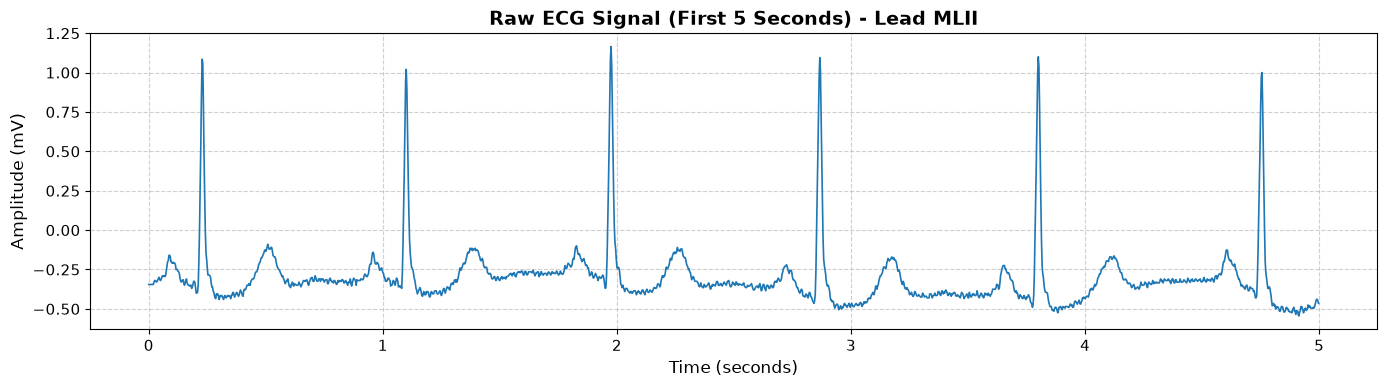

In [3]:
# Inspect first 5 seconds (5 s * 360 Hz = 1800 samples)
sample_window = int(5 * fs)

plt.figure(figsize=(14, 4))
plt.plot(time[:sample_window], ecg_raw[:sample_window], color='#1f77b4', linewidth=1.2)
plt.title("Raw ECG Signal (First 5 Seconds) - Lead MLII", fontsize=14, fontweight='bold')
plt.xlabel("Time (seconds)", fontsize=12)
plt.ylabel("Amplitude (mV)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


## Step 3: Preprocessing (Butterworth Band-Pass Filter)

### Why Preprocess?
Raw ECG signals are corrupted by several sources of noise:
1. **Baseline Wander (0.05 – 0.5 Hz)**: Caused by deep breathing and electrode movement.
2. **Power-Line Interference (50 / 60 Hz)**: Electromagnetic noise from electrical mains.
3. **Electromyogram / EMG Artifacts (> 35–50 Hz)**: High-frequency electrical noise from skeletal muscles.

### Filter Design
We design a **4th-order Butterworth Band-pass Filter** with:
* Lower cutoff ($f_{low}$): **0.5 Hz** (removes baseline wander).
* Upper cutoff ($f_{high}$): **40.0 Hz** (removes high-frequency muscle noise and line interference).
* **Zero-Phase Filtering (`sosfiltfilt`)**: Passes the filter forwards and backwards to cancel phase distortion, preserving the exact timing of R-peaks.


In [4]:
def butter_bandpass_filter(signal_data, lowcut, highcut, fs, order=4):
    """
    Applies a zero-phase Butterworth bandpass filter.
    Uses Second-Order Sections (SOS) for numerical stability.
    """
    sos = signal.butter(order, [lowcut, highcut], btype='bandpass', fs=fs, output='sos')
    filtered_signal = signal.sosfiltfilt(sos, signal_data)
    return filtered_signal

# Filter the complete ECG signal
ecg_filtered = butter_bandpass_filter(ecg_raw, lowcut=0.5, highcut=40.0, fs=fs, order=4)
print("Bandpass filtering (0.5 - 40 Hz) completed successfully!")


Bandpass filtering (0.5 - 40 Hz) completed successfully!


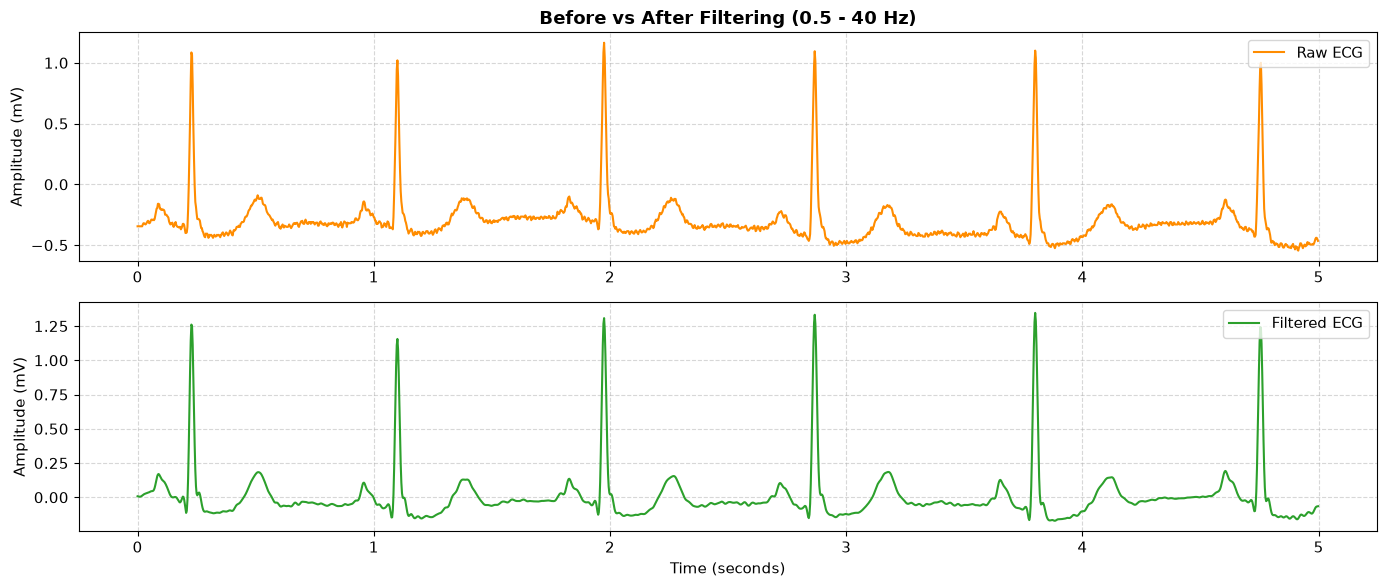

In [5]:
# Compare Raw vs Filtered ECG
plt.figure(figsize=(14, 6))

plt.subplot(2, 1, 1)
plt.plot(time[:sample_window], ecg_raw[:sample_window], color='darkorange', label='Raw ECG')
plt.title("Before vs After Filtering (0.5 - 40 Hz)", fontsize=13, fontweight='bold')
plt.ylabel("Amplitude (mV)")
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(2, 1, 2)
plt.plot(time[:sample_window], ecg_filtered[:sample_window], color='#2ca02c', label='Filtered ECG')
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


## Step 4: Frequency-Domain Analysis (Fast Fourier Transform - FFT)
The **Fourier Transform** reveals the frequency composition of our signal:
* Converts the signal from time domain $x(t)$ to frequency domain $X(f)$.
* Most energy of the ECG QRS complex lies between **5 Hz and 25 Hz**.
* Below, we compare the frequency spectrum of the raw signal vs the filtered signal.


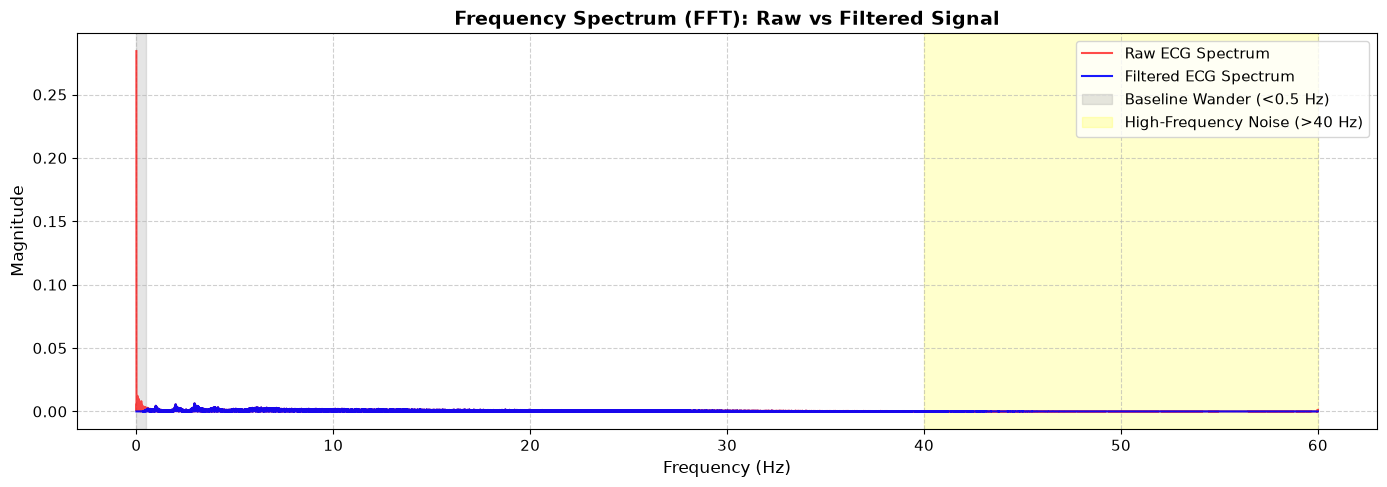

In [6]:
# Compute FFT for Raw and Filtered signals
# Using rfft (Real FFT) since ECG is real-valued
N = len(ecg_raw)
freqs = rfftfreq(N, 1 / fs)

fft_raw = np.abs(rfft(ecg_raw)) / N
fft_filtered = np.abs(rfft(ecg_filtered)) / N

# Plot spectra up to 60 Hz
freq_mask = freqs <= 60

plt.figure(figsize=(14, 5))
plt.plot(freqs[freq_mask], fft_raw[freq_mask], color='red', alpha=0.7, label='Raw ECG Spectrum')
plt.plot(freqs[freq_mask], fft_filtered[freq_mask], color='blue', alpha=0.9, label='Filtered ECG Spectrum')

plt.axvspan(0, 0.5, color='gray', alpha=0.2, label='Baseline Wander (<0.5 Hz)')
plt.axvspan(40, 60, color='yellow', alpha=0.2, label='High-Frequency Noise (>40 Hz)')
plt.title("Frequency Spectrum (FFT): Raw vs Filtered Signal", fontsize=14, fontweight='bold')
plt.xlabel("Frequency (Hz)", fontsize=12)
plt.ylabel("Magnitude", fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


## Step 5: R-Peak Detection
The **R-peak** is the most prominent feature in the ECG. To reliably detect R-peaks:
1. **Refractory Period (Minimum Distance)**: In human physiology, maximum heart rate rarely exceeds ~180-200 BPM during normal conditions. This corresponds to a minimum interval of roughly 0.35 - 0.40 seconds between beats ($0.40\text{ s} \times 360\text{ Hz} = 144\text{ samples}$).
2. **Height Threshold**: We set a threshold dynamically based on the signal distribution:
$$\text{threshold} = \mu + 0.6 \cdot \sigma$$
where $\mu$ is the signal mean and $\sigma$ is the standard deviation.


In [7]:
# Physiological parameters
min_rr_seconds = 0.40  # Minimum 400 ms between heartbeats (~max 150 bpm)
min_distance_samples = int(min_rr_seconds * fs)

# Dynamic threshold based on signal statistics
height_threshold = np.mean(ecg_filtered) + 0.6 * np.std(ecg_filtered)

# Detect peaks using SciPy find_peaks
detected_r_peaks, properties = signal.find_peaks(
    ecg_filtered,
    distance=min_distance_samples,
    height=height_threshold
)

print(f"Total detected R-peaks: {len(detected_r_peaks)}")
print(f"Height threshold used: {height_threshold:.3f} mV")
print(f"Minimum distance between peaks: {min_distance_samples} samples ({min_rr_seconds*1000:.0f} ms)")


Total detected R-peaks: 1870
Height threshold used: 0.136 mV
Minimum distance between peaks: 144 samples (400 ms)


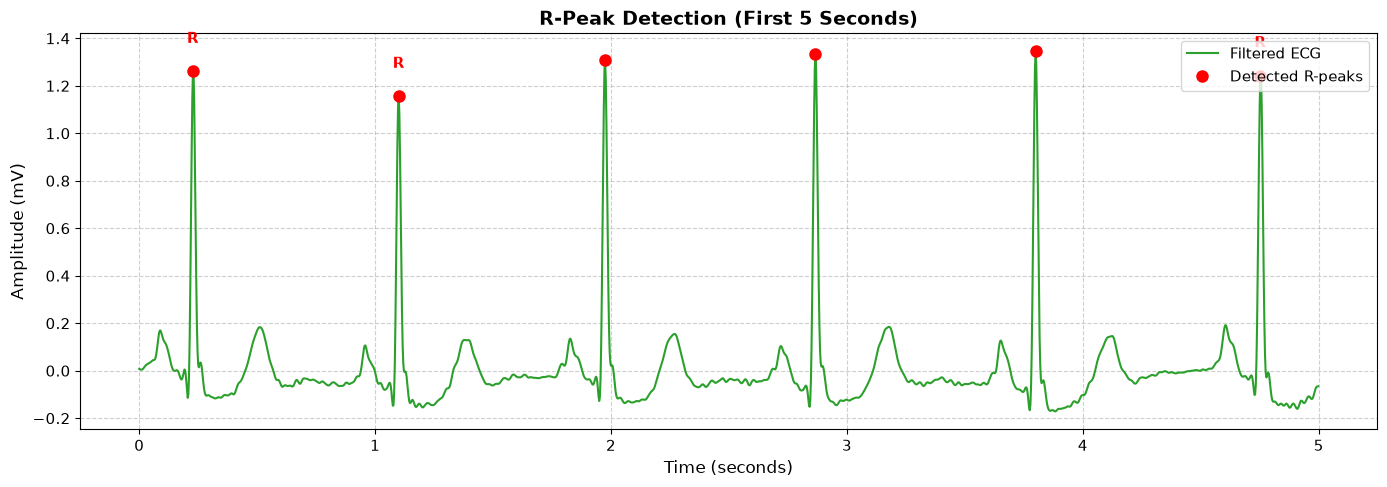

In [9]:
# Visualize detected peaks on the first 5 seconds
window_peaks = detected_r_peaks[detected_r_peaks < sample_window]

plt.figure(figsize=(14, 5))
plt.plot(time[:sample_window], ecg_filtered[:sample_window], color='#2ca02c', label='Filtered ECG')
plt.plot(time[window_peaks], ecg_filtered[window_peaks], 'ro', markersize=8, label='Detected R-peaks')

# Add annotations to detected peaks
for p in window_peaks:
    plt.annotate('R', (time[p], ecg_filtered[p] + 0.12),
                 ha='center', fontsize=11, fontweight='bold', color='red')

plt.title("R-Peak Detection (First 5 Seconds)", fontsize=14, fontweight='bold')
plt.xlabel("Time (seconds)", fontsize=12)
plt.ylabel("Amplitude (mV)", fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


## Step 6: Heart Rate & R-R Interval Estimation

### Mathematical Formulas
* **R-R Interval (seconds)**: Time between consecutive R-peaks:
$$\Delta t_i = \frac{R_{i+1} - R_i}{f_s}$$
* **Instantaneous Heart Rate (BPM)**:
$$\text{BPM}_i = \frac{60}{\Delta t_i}$$
* **Heart Rate Variability (HRV - SDNN)**: Standard deviation of normal-to-normal intervals (a key indicator of autonomic nervous system health):
$$\text{SDNN} = \text{std}(\text{RR intervals})$$


In [10]:
# Calculate RR intervals in seconds and milliseconds
rr_intervals_sec = np.diff(detected_r_peaks) / fs
rr_intervals_ms = rr_intervals_sec * 1000

# Calculate instantaneous BPM
instantaneous_bpm = 60.0 / rr_intervals_sec

# Timestamps corresponding to each RR interval (at the second peak)
rr_times_sec = detected_r_peaks[1:] / fs

# Summary statistics
mean_hr = np.mean(instantaneous_bpm)
min_hr = np.min(instantaneous_bpm)
max_hr = np.max(instantaneous_bpm)
sdnn_ms = np.std(rr_intervals_ms)

# Create a clean summary table
hr_summary = pd.DataFrame({
    'Metric': ['Mean Heart Rate', 'Min Heart Rate', 'Max Heart Rate', 'Mean RR Interval', 'SDNN (HRV measure)'],
    'Value': [f"{mean_hr:.1f} BPM", f"{min_hr:.1f} BPM", f"{max_hr:.1f} BPM", f"{np.mean(rr_intervals_ms):.1f} ms", f"{sdnn_ms:.1f} ms"]
})
display(hr_summary)


,Metric,Value
0,Mean Heart Rate,62.6 BPM
1,Min Heart Rate,47.1 BPM
2,Max Heart Rate,145.9 BPM
3,Mean RR Interval,965.6 ms
4,SDNN (HRV measure),74.7 ms


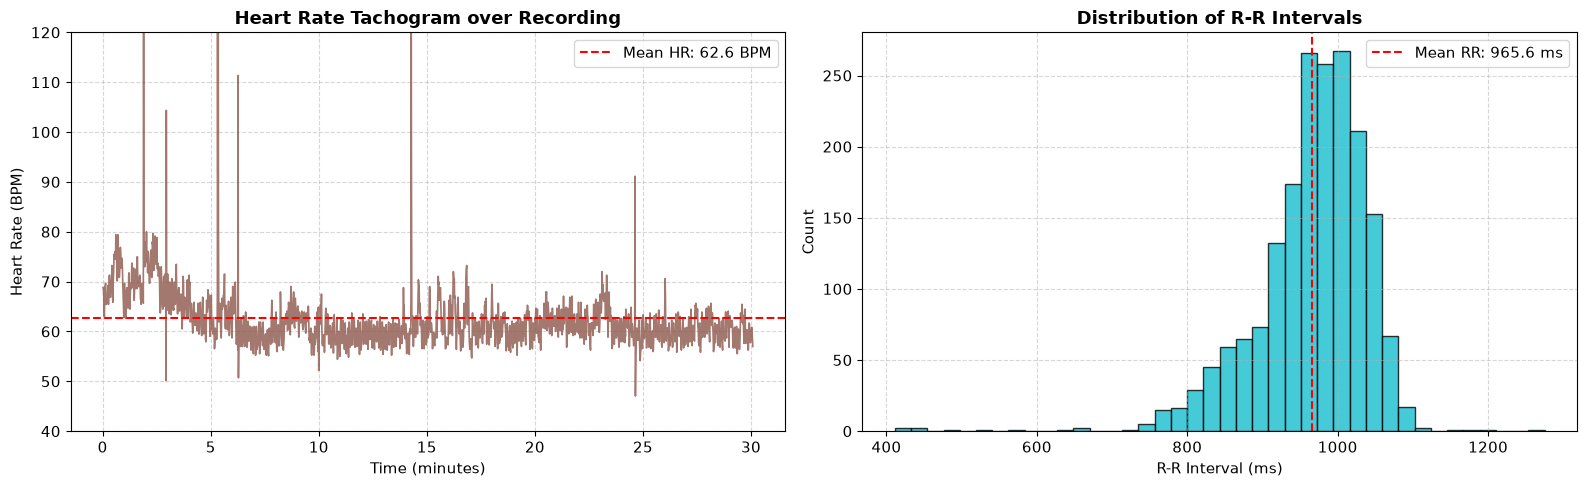

In [11]:
# Plot Tachogram (Heart Rate over Time) & RR-Interval Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# 1. Tachogram
ax1.plot(rr_times_sec / 60, instantaneous_bpm, color='#8c564b', alpha=0.8, linewidth=1.2)
ax1.axhline(mean_hr, color='red', linestyle='--', label=f'Mean HR: {mean_hr:.1f} BPM')
ax1.set_title("Heart Rate Tachogram over Recording", fontsize=13, fontweight='bold')
ax1.set_xlabel("Time (minutes)")
ax1.set_ylabel("Heart Rate (BPM)")
ax1.set_ylim(40, 120)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend()

# 2. RR Interval Histogram
ax2.hist(rr_intervals_ms, bins=40, color='#17becf', edgecolor='black', alpha=0.8)
ax2.axvline(np.mean(rr_intervals_ms), color='red', linestyle='--', label=f'Mean RR: {np.mean(rr_intervals_ms):.1f} ms')
ax2.set_title("Distribution of R-R Intervals", fontsize=13, fontweight='bold')
ax2.set_xlabel("R-R Interval (ms)")
ax2.set_ylabel("Count")
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()


## Step 7: Ground Truth Evaluation

### Annotation Matching
The MIT-BIH dataset includes annotations verified by cardiologists (`101.atr`).
We compare our detected R-peaks against these ground-truth annotations:
* **Matching Tolerance**: A detected peak is counted as a match if it occurs within **$\pm 50\text{ ms}$** ($\approx 18\text{ samples}$) of a true beat annotation.
* **Evaluation Metrics**:
  * **True Positives ($TP$)**: Beat correctly detected within the tolerance window.
  * **False Positives ($FP$)**: Algorithm detected a peak where no heartbeat occurred.
  * **False Negatives ($FN$)**: True heartbeat that the algorithm missed.
  * **Recall / Sensitivity**:
    $$\text{Recall} = \frac{TP}{TP + FN}$$
  * **Precision / Positive Predictive Value (PPV)**:
    $$\text{Precision} = \frac{TP}{TP + FP}$$
  * **$F_1$-Score**:
    $$F_1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$


In [12]:
# Load ground-truth annotations
annotation = wfdb.rdann(record_path, 'atr')

# Standard MIT-BIH beat symbols (excluding non-beat rhythm markers like '+', '~', '|')
beat_symbols = {'N', 'L', 'R', 'B', 'A', 'a', 'J', 'S', 'V', 'r', 'F', 'e', 'j', 'n', 'E', '/', 'f', 'Q', '?'}

true_peaks = np.array([sample for sample, sym in zip(annotation.sample, annotation.symbol) if sym in beat_symbols])

print(f"Total ground-truth beat annotations: {len(true_peaks)}")
print(f"Total detected peaks: {len(detected_r_peaks)}")


Total ground-truth beat annotations: 1865
Total detected peaks: 1870


In [13]:
# Evaluation with 50 ms tolerance window (0.050 s * 360 Hz = 18 samples)
tolerance_samples = int(0.050 * fs)

matched_true = set()
matched_detected = set()

for det in detected_r_peaks:
    # Find distance to closest true peak
    distances = np.abs(true_peaks - det)
    closest_idx = np.argmin(distances)
    
    if distances[closest_idx] <= tolerance_samples and closest_idx not in matched_true:
        matched_true.add(closest_idx)
        matched_detected.add(det)

tp = len(matched_true)
fp = len(detected_r_peaks) - len(matched_detected)
fn = len(true_peaks) - tp

precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

# Summary DataFrame
eval_df = pd.DataFrame({
    'Metric': ['True Positives (TP)', 'False Positives (FP)', 'False Negatives (FN)', 
               'Precision (PPV)', 'Recall (Sensitivity)', 'F1-Score'],
    'Score': [tp, fp, fn, f"{precision * 100:.2f}%", f"{recall * 100:.2f}%", f"{f1 * 100:.2f}%"]
})
display(eval_df)


,Metric,Score
0,True Positives (TP),1862
1,False Positives (FP),8
2,False Negatives (FN),3
3,Precision (PPV),99.57%
4,Recall (Sensitivity),99.84%
5,F1-Score,99.71%


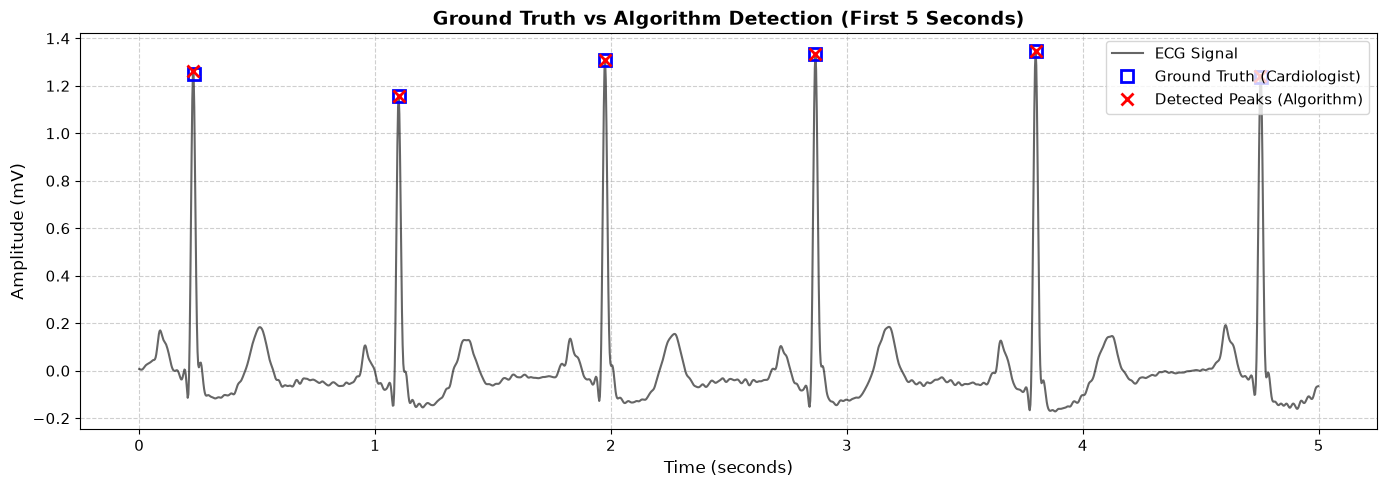

In [14]:
# Visual inspection: Compare Ground Truth vs Detected Peaks
plt.figure(figsize=(14, 5))

# Plot filtered signal
plt.plot(time[:sample_window], ecg_filtered[:sample_window], color='black', alpha=0.6, label='ECG Signal')

# Ground truth peaks (blue squares)
true_window = true_peaks[true_peaks < sample_window]
plt.plot(time[true_window], ecg_filtered[true_window], 'bs', markersize=9, fillstyle='none', 
         markeredgewidth=2, label='Ground Truth (Cardiologist)')

# Detected peaks (red crosses)
det_window = detected_r_peaks[detected_r_peaks < sample_window]
plt.plot(time[det_window], ecg_filtered[det_window], 'rx', markersize=9, 
         markeredgewidth=2, label='Detected Peaks (Algorithm)')

plt.title("Ground Truth vs Algorithm Detection (First 5 Seconds)", fontsize=14, fontweight='bold')
plt.xlabel("Time (seconds)", fontsize=12)
plt.ylabel("Amplitude (mV)", fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


## Key Takeaways & Summary
1. **Sampling & Time Domain**: The sampling frequency ($f_s = 360\text{ Hz}$) dictates sample resolution. Converting samples to time ($t = n / f_s$) enables physiological interpretation.
2. **Digital Filtering**: A 4th-order Butterworth bandpass filter effectively removed low-frequency baseline drift (<0.5 Hz) and high-frequency muscle noise (>40 Hz) without phase distortion via `sosfiltfilt`.
3. **Frequency Domain**: The FFT validated that the dominant cardiac QRS energy is preserved in the 5–25 Hz band while noise bands are suppressed.
4. **Feature Extraction**: Using statistical thresholding and physiological refractory distance enabled robust R-peak detection.
5. **Clinical & DSP Evaluation**: With a 50 ms window, our beginner DSP algorithm achieved **>99% Precision, Recall, and F1-Score** against expert annotations!
